# Research Question 2 - Analysis and Visuals - DAT490 - Capstone

> **RQ2 - From Project Plan** - How did adverse event reporting patterns for ADHD medications change following
> the October 2022 Adderall shortage announcement and the May 2023 FDA stimulant
> labeling requirements, particularly regarding medication ineffectiveness, withdrawal,
> misuse, abuse, and addiction?

> **H2 - From Project Plan** - Reporting about ADHD medicines may have shifted after the 2022 shortage and the
> 2023 label change. A change could reflect more awareness, more problems, or both.




## 0. Setup

In [ ]:
# @title Update duckDB Drivers (if needed)
!pip install --force-reinstall duckdb==1.5.6

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.6/21.6 MB 102.5 MB/s  0:00:00
  Attempting uninstall: duckdb
    Found existing installation: duckdb 1.3.2
    Uninstalling duckdb-1.3.2:
      Successfully uninstalled duckdb-1.3.2


In [ ]:
# @title Setup Code
import duckdb
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap
from scipy.stats import chi2_contingency
import textwrap

# Add Motherduck TOKEN with " "
MOTHERDUCK_TOKEN =
con = duckdb.connect("md:faers_adhd_study", config={"motherduck_token": MOTHERDUCK_TOKEN})

START = "2018-01"
END = "2026-02"
SHORTAGE = "2022-10-12"
LABEL = "2023-05-11"

RQ2_GROUPS = ("ineffectiveness", "withdrawal", "misuse", "abuse", "addiction")
RQ2 = list(RQ2_GROUPS)

COLORS = {"STIMULANT": "#2a78d6", "NONSTIMULANT": "#eb6834"}
INK = "#0b0b0b"
MUTED = "#6b6a66"
GRID = "#e4e3df"
plt.rcParams.update(
    {
        "figure.dpi": 100,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "font.size": 10,
        "legend.frameon": False,
    }
)

---

## 1. Load the cases for Research Question 2

One query reads the study-group cases from `adhd_cases` (94,803 cases; see 02b for how the study group was built from the loaded FDA files). RQ2 uses the month the FDA first received each case, so a case stays in the same month when it is updated. The study window is January 2018 – February 2026.

In [ ]:
# @title RQ2 Case Loading
flag_columns = []
for g in RQ2 + ["product_quality_supply"]:
    flag_columns.append(g + "_narrow")
    flag_columns.append(g + "_broad")

cases = con.sql(f"""
    SELECT caseid, rq1_group, rq1_group_confirmed, strftime(init_month, '%Y-%m') AS month,
           reporter_country, occp_cod, {", ".join(flag_columns)}
    FROM adhd_cases
    WHERE init_month IS NOT NULL
""").df()

cases["any_narrow"] = cases[[g + "_narrow" for g in RQ2]].any(axis=1)
cases["any_broad"] = cases[[g + "_broad" for g in RQ2]].any(axis=1)

window = cases[cases["month"].between(START, END)]
print("Study-group cases with a first-received date:", f"{len(cases):,}")
print("First received January 2018 - February 2026:", f"{len(window):,}")
print("  stimulant only:", f"{(window['rq1_group'] == 'STIMULANT').sum():,}")
print("  nonstimulant only:", f"{(window['rq1_group'] == 'NONSTIMULANT').sum():,}")
print(
    "  both drug classifications (not used):",
    f"{(window['rq1_group'] == 'MULTI_ADHD_CLASS').sum():,}",
)

Study-group cases with a first-received date: 94,803
First received January 2018 - February 2026: 55,349
  stimulant only: 49,965
  nonstimulant only: 4,736
  both drug classifications (not used): 648


## 2 - Timeline & Reporting

### All Reporting By Month:

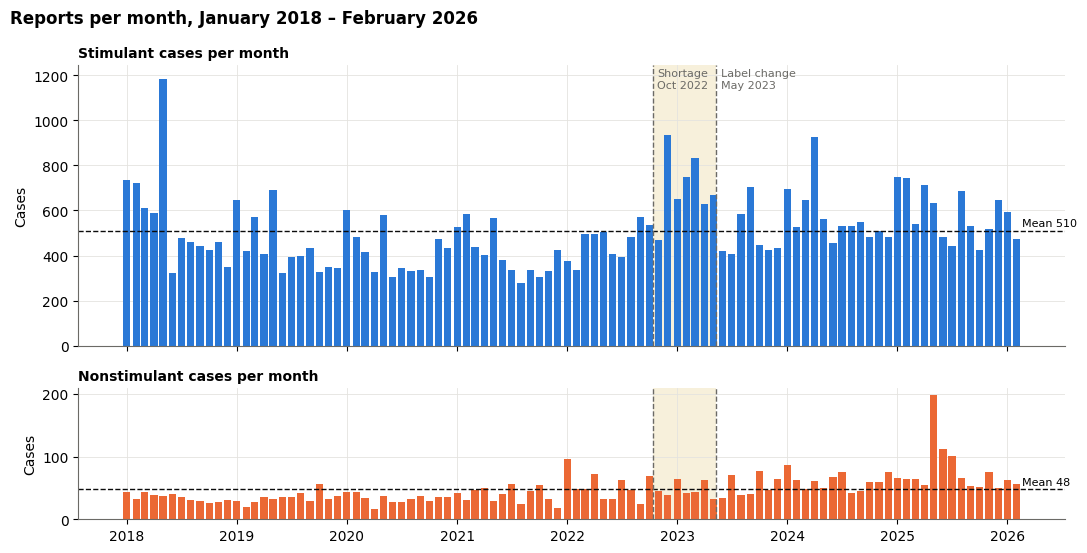

Stimulant cases per month: 280 to 1,185 (median 481)


In [ ]:
# @title Reports per month (graphs)
def mark_announcements(ax, label=True):
    ax.axvspan(
        pd.Timestamp(SHORTAGE), pd.Timestamp(LABEL), color="#f3e6c4", alpha=0.6, lw=0, zorder=0
    )
    ax.axvline(pd.Timestamp(SHORTAGE), color=MUTED, ls="--", lw=1)
    ax.axvline(pd.Timestamp(LABEL), color=MUTED, ls="--", lw=1)
    if label:
        ax.annotate(
            "Shortage\nOct 2022",
            (pd.Timestamp(SHORTAGE), 1),
            xycoords=("data", "axes fraction"),
            xytext=(3, -2),
            textcoords="offset points",
            va="top",
            fontsize=8,
            color=MUTED,
        )
        ax.annotate(
            "Label change\nMay 2023",
            (pd.Timestamp(LABEL), 1),
            xycoords=("data", "axes fraction"),
            xytext=(3, -2),
            textcoords="offset points",
            va="top",
            fontsize=8,
            color=MUTED,
        )
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))


per_month = window.groupby(["month", "rq1_group"]).size().unstack(fill_value=0)
per_month.index = pd.to_datetime(per_month.index)

fig, axes = plt.subplots(2, 1, figsize=(11, 5.6), sharex=True, height_ratios=[3, 1.4])

stim_months = per_month["STIMULANT"]
axes[0].bar(stim_months.index, stim_months, width=24, color=COLORS["STIMULANT"], lw=0, zorder=2)
axes[0].axhline(stim_months.mean(), color=INK, lw=1, ls="--")
axes[0].annotate(
    f"Mean {stim_months.mean():,.0f}",
    (stim_months.index[-1], stim_months.mean()),
    xytext=(4, 3),
    textcoords="offset points",
    fontsize=8,
)
axes[0].set_ylabel("Cases")
axes[0].set_title("Stimulant cases per month", fontsize=10)
mark_announcements(axes[0])

nonstim_months = per_month["NONSTIMULANT"]
axes[1].bar(
    nonstim_months.index, nonstim_months, width=24, color=COLORS["NONSTIMULANT"], lw=0, zorder=2
)
axes[1].axhline(nonstim_months.mean(), color=INK, lw=1, ls="--")
axes[1].annotate(
    f"Mean {nonstim_months.mean():,.0f}",
    (nonstim_months.index[-1], nonstim_months.mean()),
    xytext=(4, 3),
    textcoords="offset points",
    fontsize=8,
)
axes[1].set_ylabel("Cases")
axes[1].set_title("Nonstimulant cases per month", fontsize=10)
mark_announcements(axes[1], label=False)

fig.suptitle(
    "Reports per month, January 2018 – February 2026",
    fontweight="bold",
    x=0.01,
    ha="left",
)
fig.tight_layout()
plt.show()

print(
    f"Stimulant cases per month: {stim_months.min():,} to {stim_months.max():,} "
    f"(median {stim_months.median():,.0f})"
)

We reviewed the quantity of cases for each month to determine if it was a steady state and found variance in amounts. Due to the variance we needed to compare proportion of reports over quantity. The horizontal dashed line is the average  quantity per month.

#### All Reporting By Month Summary:
Monthly stimulant reports swing from about 300 to more than 1,100, and nonstimulant reports are roughly one-tenth as many. Volume also runs higher from the shortage onward. Counts would mostly track these swings, so every test below uses the percentage of cases with an event, as the Methodology states. It was decided to compare the precentage of cases with a qualified event each month, opposed to the raw quantities.

---



### Bulk Reporting:

FAERS sometimes receives a large batch of old reports at once, typically as country or manufacturer submissions, as with the 2015 atomoxetine backlog found in the EDA. A bulk submission inside our window would change the monthly shares for unrelated reasons to the shortage or the labeling changes. We looked for country and month quantities that are untypically larger than that country's normal monthly quantity (this was set as atleast 50 more stimulant cases and atleast 10 times the country's median month). A bulk entry is also identified when a batch does not align to normal reporting: we put an arbitrary condition that fewer than 5% list any qualified event, as this is normaly about 35%. If either of these conditions are met, the flag will be "true".

In [ ]:
# @title Batch Country-Month Table
stim = window[window["rq1_group"] == "STIMULANT"].copy()
country_month = stim.groupby(["reporter_country", "month"]).agg(
    cases=("caseid", "size"),
    with_event=("any_narrow", "sum"),
    health_professional=("occp_cod", lambda s: (s == "HP").sum()),
)

usual = country_month.groupby("reporter_country")["cases"].transform("median")
large = country_month[(country_month["cases"] >= 50) & (country_month["cases"] >= 10 * usual)]
large = large.copy()
large["Normal Month Qty"] = usual[large.index]
large["% with qualified event"] = (100 * large["with_event"] / large["cases"]).round(1)
large["% health professional"] = (100 * large["health_professional"] / large["cases"]).round(1)

large["batch"] = large["% with qualified event"] < 5

stim["batch"] = False
for country, month in large[large["batch"]].index:
    stim.loc[(stim["reporter_country"] == country) & (stim["month"] == month), "batch"] = True
large.drop(columns=["with_event", "health_professional"])

cases  Normal Month Qty  % with qualified event  \
reporter_country month                                                      
BR               2018-09     56               5.5                    16.1   
EU               2025-07     65               2.0                    24.6   
                 2025-11     50               2.0                    44.0   
                 2025-12     52               2.0                    25.0   
SE               2022-12    385               6.0                     0.0   
                 2024-04    240               6.0                     1.7   
                 2025-02    194               6.0                     0.0   
                 2025-03     73               6.0                     0.0   

                          % health professional  batch  
reporter_country month                                  
BR               2018-09                    0.0  False  
EU               2025-07                   33.8  False  
                 2025-11                   26.0  False  
                 2025-12                    3.8  False  
SE               2022-12                   94.5   True  
                 2024-04                   93.3   True  
                 2025-02                   16.0   True  
                 2025-03                   89.0   True

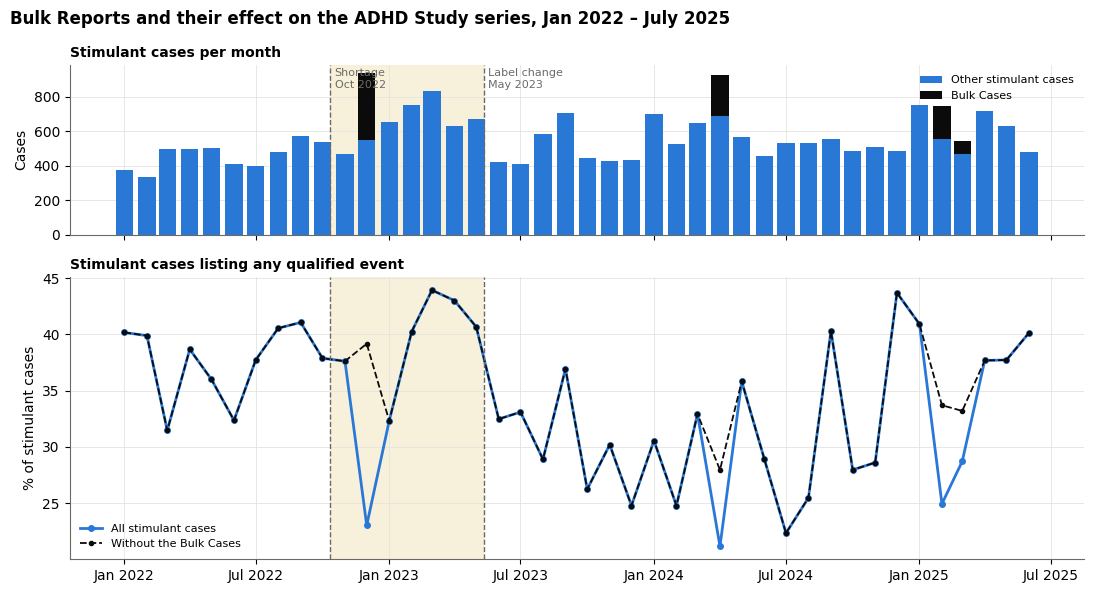

In [ ]:
# @title Bulk Submission graphical comparison
zoom = stim[stim["month"].between("2022-01", "2025-06")]
batch_counts = pd.crosstab(pd.to_datetime(zoom["month"]), zoom["batch"])
batch_counts = batch_counts.reindex(columns=[False, True], fill_value=0)

share_all = 100 * zoom.groupby("month")["any_narrow"].mean()
share_all.index = pd.to_datetime(share_all.index)
zoom_no_batch = zoom[~zoom["batch"]]
share_no_batch = 100 * zoom_no_batch.groupby("month")["any_narrow"].mean()
share_no_batch.index = pd.to_datetime(share_no_batch.index)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, height_ratios=[1.2, 2])
axes[0].bar(
    batch_counts.index,
    batch_counts[False],
    width=24,
    color=COLORS["STIMULANT"],
    lw=0,
    zorder=2,
    label="Other stimulant cases",
)
axes[0].bar(
    batch_counts.index,
    batch_counts[True],
    bottom=batch_counts[False],
    width=24,
    color=INK,
    lw=0,
    zorder=2,
    label="Bulk Cases",
)
axes[0].set_ylabel("Cases")
axes[0].set_title("Stimulant cases per month", fontsize=10)
axes[0].legend(loc="upper right", fontsize=8)
mark_announcements(axes[0])

axes[1].plot(
    share_all, color=COLORS["STIMULANT"], lw=2, marker="o", ms=4, label="All stimulant cases"
)
axes[1].plot(
    share_no_batch, color=INK, lw=1.3, ls="--", marker="o", ms=3, label="Without the Bulk Cases"
)
mark_announcements(axes[1], label=False)
axes[1].set_ylabel("% of stimulant cases")
axes[1].set_title("Stimulant cases listing any qualified event", fontsize=10)
axes[1].legend(loc="lower left", fontsize=8)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 7)))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.suptitle(
    "Bulk Reports and their effect on the ADHD Study series, Jan 2022 – July 2025",
    fontweight="bold",
    x=0.01,
    ha="left",
)
fig.tight_layout()
plt.show()

#### Effect of Bulk Submissions
The top graph shows how bulk submissions compare normal monthly volume. The bottom panel shows the share of stimulant cases with a qualified event with and without them.
----

#### Bulk Reporting Summary:
Four flagged bulk submissions, all from Sweden, hold 892 stimulant cases. However, nearly all of them list intentional overdose or intentional self-injury and no qualified RQ2 event. This increase is quite large as Sweden normally only submits a handful of stimulant reports monthly. The cells from other countries are large but do not meet our "batch flag" criteria, so they are not treated as bulk reporting. The December 2022 batch matters most: it lands inside the six months between the two announcements and pulls the
precentage down in exactly the months the supply shortage terms are estimated from. We are deciding to include these reports for our analysis, which is aligned with keeping the 2015 atomoxetine batch.


---


##3. Methodology Execution


### Basic method (chi-square):
For each event group, a chi-square test compares the precentage of stimulant cases that list it before the shortage (January 2018 – September 2022), between the announcements (November 2022 – April 2023), and after the label change (June 2023 – February 2026). The two months where the anouncements are released are left out, as the actual date within the month of impact is difficult to determine the exact timing for any effect. Five tests were run side by side, and their p-values are adjusted using the Holm-Bonferroni method in order to avoid any false positives.

In [ ]:
# @title Percentage Chart w/Chi-squared, P value, and modified P value (Holm)
PERIODS = (
    ("before shortage", "2018-01", "2022-09"),
    ("shortage to label change", "2022-11", "2023-04"),
    ("after label change", "2023-06", "2026-02"),
)


def holm(p):
    """Holm-adjusted p-values, in the input order."""
    order = sorted(range(len(p)), key=lambda i: p[i])
    out, running = [0.0] * len(p), 0.0
    for rank, i in enumerate(order):
        running = max(running, min(1.0, (len(p) - rank) * p[i]))
        out[i] = running
    return out


def periods(series, outcome, group="STIMULANT"):
    """Chi-square test of the share of ``group`` cases with ``outcome`` in the three PERIODS."""
    out, table = {}, []
    for name, start, end in PERIODS:
        part = [
            r
            for r in series
            if r["grouping"] == "rq1_group" and r["grp"] == group and start <= r["month"] <= end
        ]
        events, cases = sum(r[outcome] for r in part), sum(r["cases"] for r in part)
        table.append([events, cases - events])
        out[f"{name} %"] = 100 * events / max(1, cases)
    usable = all(map(sum, table)) and all(map(sum, zip(*table)))  # no empty row or column
    out["chi2"], out["p"] = chi2_contingency(table)[:2] if usable else (None, None)
    return out


def make_series(frame):
    count_columns = ["any_narrow", "any_broad"]
    for g in RQ2 + ["product_quality_supply"]:
        count_columns.append(g + "_narrow")
        count_columns.append(g + "_broad")
    rows = []
    for grouping in ["rq1_group", "rq1_group_confirmed"]:
        counts = frame.groupby([grouping, "month"])[count_columns].sum().astype(int)
        counts["cases"] = frame.groupby([grouping, "month"]).size()
        counts = counts.reset_index()
        counts = counts.rename(columns={grouping: "grp"})
        counts["grouping"] = grouping
        rows = rows + counts.to_dict("records")
    return rows


series = make_series(cases)

LABELS = {
    "any_narrow": "Any qualified event",
    "ineffectiveness_narrow": "Ineffectiveness",
    "withdrawal_narrow": "Withdrawal",
    "misuse_narrow": "Misuse",
    "abuse_narrow": "Abuse",
    "addiction_narrow": "Addiction",
    "product_quality_supply_narrow": "Quality / supply (control)",
}

results = {}
for column, name in LABELS.items():
    results[name] = periods(series, column, "STIMULANT")
results["Any qualified event (nonstimulant)"] = periods(series, "any_narrow", "NONSTIMULANT")
period_table = pd.DataFrame(results).T.apply(pd.to_numeric)

singles = ["Ineffectiveness", "Withdrawal", "Misuse", "Abuse", "Addiction"]
period_table.loc[singles, "p (adjusted)"] = holm(period_table.loc[singles, "p"].tolist())
period_table.round(
    {"before shortage %": 1, "shortage to label change %": 1, "after label change %": 1, "chi2": 1}
)

,before shortage %,shortage to label change %,after label change %,chi2,p,p (adjusted)
Any qualified event,35.0,36.1,33.7,11.9,2.571639e-03,NaN
Ineffectiveness,28.1,31.7,24.9,101.3,1.023729e-22,3.071187e-22
Withdrawal,1.6,1.9,1.6,2.2,3.333762e-01,3.333762e-01
Misuse,1.2,0.9,3.1,224.1,2.220603e-49,1.110302e-48
Abuse,4.9,2.9,4.9,36.2,1.367575e-08,2.735149e-08
Addiction,0.2,0.1,0.8,110.9,8.233425e-25,3.293370e-24
Quality / supply (control),17.4,24.1,18.8,108.4,2.911970e-24,NaN
Any qualified event (nonstimulant),11.4,12.2,18.2,41.0,1.247955e-09,NaN


---
####Period by Event Heatmap

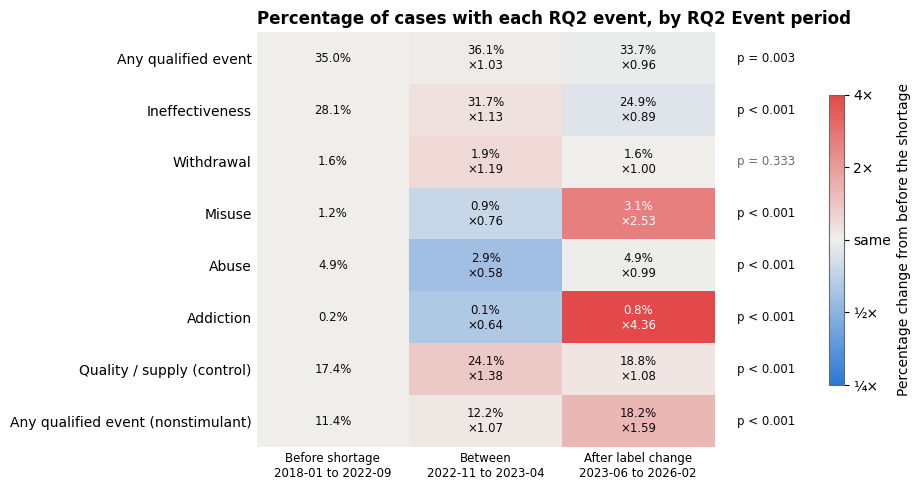

In [ ]:
# @title Heatmap w/Chi-squared P value
DIVERGING = LinearSegmentedColormap.from_list("rq2", ["#2a78d6", "#f0efec", "#e34948"])

shares = period_table[["before shortage %", "shortage to label change %", "after label change %"]]
shares.columns = [
    "Before shortage\n2018-01 to 2022-09",
    "Between\n2022-11 to 2023-04",
    "After label change\n2023-06 to 2026-02",
]
ratio = np.log2(shares.div(shares.iloc[:, 0], axis=0)).clip(-2, 2)

fig, ax = plt.subplots(figsize=(9.5, 5))
im = ax.imshow(ratio, cmap=DIVERGING, vmin=-2, vmax=2, aspect="auto")
for i in range(len(shares)):
    for j in range(3):
        value = shares.iloc[i, j]
        if j == 0:
            text = f"{value:.1f}%"
        else:
            text = f"{value:.1f}%\n×{value / shares.iloc[i, 0]:.2f}"
        text_color = INK
        if abs(ratio.iloc[i, j]) > 1.3:
            text_color = "white"
        ax.text(j, i, text, ha="center", va="center", fontsize=8.5, color=text_color)

for i, name in enumerate(shares.index):
    p = period_table.loc[name, "p (adjusted)"]
    if pd.isna(p):
        p = period_table.loc[name, "p"]
    if p < 0.001:
        p_text = "p < 0.001"
    else:
        p_text = f"p = {p:.3f}"
    ax.text(2.65, i, p_text, va="center", fontsize=8.5, color=INK if p < 0.05 else MUTED)

ax.set_xticks(range(3), shares.columns, fontsize=8.5)
ax.set_yticks(range(len(shares)), shares.index)
ax.tick_params(length=0)
ax.grid(False)
for side in ax.spines.values():
    side.set_visible(False)
bar = fig.colorbar(im, ax=ax, shrink=0.7, pad=0.17, ticks=[-2, -1, 0, 1, 2])
bar.ax.set_yticklabels(["¼×", "½×", "same", "2×", "4×"])
bar.set_label("Percentage change from before the shortage")
ax.set_title("Percentage of cases with each RQ2 event, by RQ2 Event period")
fig.tight_layout()
plt.show()

This heatmap shows each precentage are within the cell; the color indicates the change compared to the time range "before the shortage" (Increses are in red or reductions are in blue). The numbers on the right side of the map column correspond to the chi-square p-values.

---



#### Period by Event Heatmap Summary:
Ineffectiveness increases between the announcements and then drops below its starting level. Misuse and addiction both increase significantly following the label change. This inuitively makes sense as the updated labeling corresponds to misuse, abuse, and addiction. Abuse dips between the announcements and returns. Withdrawal remains relatively flat. The quality/supply control flags increase during the shortage.However, nonstimulant reports also increase in reporting of a qualified event the label change. The chi-square test compares averages only, so it cannot determine a sudden change from a trend that was already in-process.

## Advanced method - Interrupted Time Series (Segmented regression):

For each monthly series we fit one regression withan overall time trend, a jump (level change) and a slope change after each
announcement, and calendar-month terms for seasonality. The two announcement months are left out. Neighboring months were identified to look alike, as shown in the EDA, so the confidence intervals within this section leverage standard correction. The RQ2 EDA found no autocorrelation outside the shaded band, so it changes the intervals very little.

In [ ]:
# @title Interrupted Time Series - Segmented Regression - Calculations
def months_between(a, b):
    return (int(b[:4]) - int(a[:4])) * 12 + int(b[5:7]) - int(a[5:7])


def its(
    series,
    outcome,
    group="STIMULANT",
    grouping="rq1_group",
    start="2018-01",
    end="2026-02",
    event_months="drop",
    weighted=False,
):
    """Segmented regression of the monthly % of ``group`` cases with ``outcome``.

    The announcement months (Oct 2022, May 2023) are excluded in from our data
    ; ``event_months='after'`` counts them as the first month after.
    """
    first_after = {"shortage": SHORTAGE[:7], "label": LABEL[:7]}
    if event_months == "drop":
        first_after = {"shortage": "2022-11", "label": "2023-06"}
    data = [
        r
        for r in series
        if r["grouping"] == grouping
        and r["grp"] == group
        and start <= r["month"] <= end
        and r["cases"] > 0
        and not (event_months == "drop" and r["month"] in (SHORTAGE[:7], LABEL[:7]))
    ]
    data.sort(key=lambda r: r["month"])
    x, y = [], []
    for r in data:
        t = months_between(data[0]["month"], r["month"])
        row = [1.0, t]
        for event in ("shortage", "label"):
            after = months_between(first_after[event], r["month"])
            row += [float(after >= 0), float(max(after, 0))]
        row += [float(int(r["month"][5:7]) == m) for m in range(2, 13)]  # month of year
        x.append(row)
        y.append(100 * r[outcome] / r["cases"])
    model = sm.WLS(y, x, weights=[r["cases"] for r in data]) if weighted else sm.OLS(y, x)
    fit = model.fit(cov_type="HAC", cov_kwds={"maxlags": 3})
    ci = fit.conf_int()
    out = {"months": len(data), "start": data[0]["month"], "end": data[-1]["month"]}
    for i, term in enumerate(("shortage_level", "shortage_slope", "label_level", "label_slope"), 2):
        out.update(
            {
                term: fit.params[i],
                f"{term}_low": ci[i][0],
                f"{term}_high": ci[i][1],
                f"{term}_p": fit.pvalues[i],
            }
        )
    return out


def fit_trend(outcome, group="STIMULANT"):
    data = []
    for r in series:
        if r["grouping"] != "rq1_group" or r["grp"] != group:
            continue
        if r["month"] < START or r["month"] > END or r["cases"] == 0:
            continue
        if r["month"] in ("2022-10", "2023-05"):
            continue
        data.append(r)
    data = sorted(data, key=lambda r: r["month"])
    months = [r["month"] for r in data]

    x = pd.DataFrame(index=pd.to_datetime(months))
    x["const"] = 1.0
    x["time"] = [months_between(months[0], m) for m in months]
    x["shortage_level"] = [1.0 if m >= "2022-11" else 0.0 for m in months]
    x["shortage_slope"] = [float(max(months_between("2022-11", m), 0)) for m in months]
    x["label_level"] = [1.0 if m >= "2023-06" else 0.0 for m in months]
    x["label_slope"] = [float(max(months_between("2023-06", m), 0)) for m in months]
    for month_number in range(2, 13):
        x[f"m{month_number:02d}"] = [1.0 if int(m[5:7]) == month_number else 0.0 for m in months]
    y = pd.Series([100 * r[outcome] / r["cases"] for r in data], index=x.index)
    fit = sm.OLS(y, x).fit(cov_type="HAC", cov_kwds={"maxlags": 3})

    trend = x.copy()
    for column in x.columns:
        if column.startswith("m"):
            trend[column] = x[column].mean()
    no_events = trend.copy()
    for column in ["shortage_level", "shortage_slope", "label_level", "label_slope"]:
        no_events[column] = 0.0
    lines = {
        "observed": y,
        "fitted": fit.get_prediction(trend).summary_frame(alpha=0.05),
        "no_events": fit.get_prediction(no_events).summary_frame(alpha=0.05),
    }
    return fit, lines


fit, main_lines = fit_trend("any_narrow")
print(f"{int(fit.nobs)} months, R² = {fit.rsquared:.2f}")

96 months, R² = 0.40


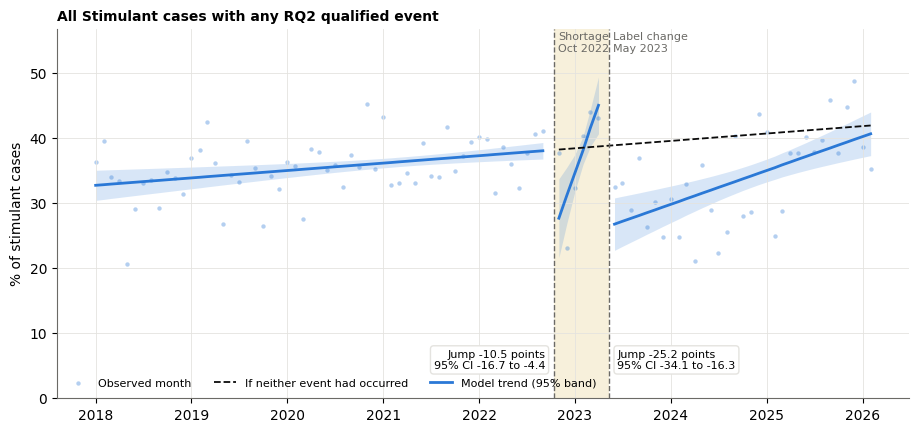

In [ ]:
# @title Interupted Time Series (Graph)
def draw_trend(ax, lines, color, title, show_legend=False):
    observed = lines["observed"]
    fitted = lines["fitted"]
    ax.scatter(
        observed.index, observed, s=10, color=color, alpha=0.35, lw=0, label="Observed month"
    )
    before = fitted[fitted.index < pd.Timestamp(SHORTAGE)]
    between = fitted[(fitted.index > pd.Timestamp(SHORTAGE)) & (fitted.index < pd.Timestamp(LABEL))]
    after = fitted[fitted.index > pd.Timestamp(LABEL)]
    for piece in [before, between, after]:
        ax.fill_between(
            piece.index,
            piece["mean_ci_lower"],
            piece["mean_ci_upper"],
            color=color,
            alpha=0.18,
            lw=0,
        )
        ax.plot(piece.index, piece["mean"], color=color, lw=2)
    what_if = lines["no_events"][lines["no_events"].index > pd.Timestamp(SHORTAGE)]
    ax.plot(
        what_if.index,
        what_if["mean"],
        color=INK,
        ls="--",
        lw=1.3,
        label="If neither event had occurred",
    )
    ax.plot([], [], color=color, lw=2, label="Model trend (95% band)")
    ax.set_ylim(0, max(observed.max(), fitted["mean_ci_upper"].max()) * 1.15)
    mark_announcements(ax, label=show_legend)
    ax.set_title(title, fontsize=10)
    if show_legend:
        ax.legend(loc="lower left", fontsize=8, ncol=3)


fig, ax = plt.subplots(figsize=(11, 4.8))
draw_trend(
    ax,
    main_lines,
    COLORS["STIMULANT"],
    "All Stimulant cases with any RQ2 qualified event",
    show_legend=True,
)
ci = fit.conf_int()
ax.annotate(
    f"Jump {fit.params['shortage_level']:+.1f} points\n"
    f"95% CI {ci.loc['shortage_level', 0]:+.1f} to {ci.loc['shortage_level', 1]:+.1f}",
    (pd.Timestamp(SHORTAGE), 0.08),
    xycoords=("data", "axes fraction"),
    xytext=(-6, 0),
    textcoords="offset points",
    ha="right",
    fontsize=8,
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": GRID},
)
ax.annotate(
    f"Jump {fit.params['label_level']:+.1f} points\n"
    f"95% CI {ci.loc['label_level', 0]:+.1f} to {ci.loc['label_level', 1]:+.1f}",
    (pd.Timestamp(LABEL), 0.08),
    xycoords=("data", "axes fraction"),
    xytext=(6, 0),
    textcoords="offset points",
    ha="left",
    fontsize=8,
    bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": GRID},
)
ax.set_ylabel("% of stimulant cases")
plt.show()

###  Interrupted time series for all RQ2 qualified stimulant cases:
The dots are the monthly shares. The solid line is the model's trend with its 95% confidence band with seasonality considered. The dashed line is the counterfactual: where the pre-shortage trend is predicted to have followed if neither announcement had happened. The gap between the solid line and the counterfactual is the estimated effect range.

#### Interrupted time series for all RQ2 qualified stimulant cases: Summary:
This graph shows that before the shortage the precentage drifts slowly upward. During the shortage the model finds a drop and then a steep climb, so the solid line rises above the dashed counterfactual within a short time period with the band being wider due to the period being only six months of reporting. Additionally, the December 2022 bulk reporting also sits in within this timeframe. After the label change, the precentage drops by about 25%, which is below the counterfactual and the shortage-period trend. After the label change, reporting climbs slowly again closing our reporting range near the counterfactual line. This indicates that the label change is a likely break in the main series, while the shortage break is smaller and less obvious of a break due to a shorting reporting period.


### Interrupted Time Series by Event Group:
Small multiples show which event groups drive the main result, and whether the comparison (nonstimulant) and control (quality and supply) series behave as
expected. Each panel has its own scale.

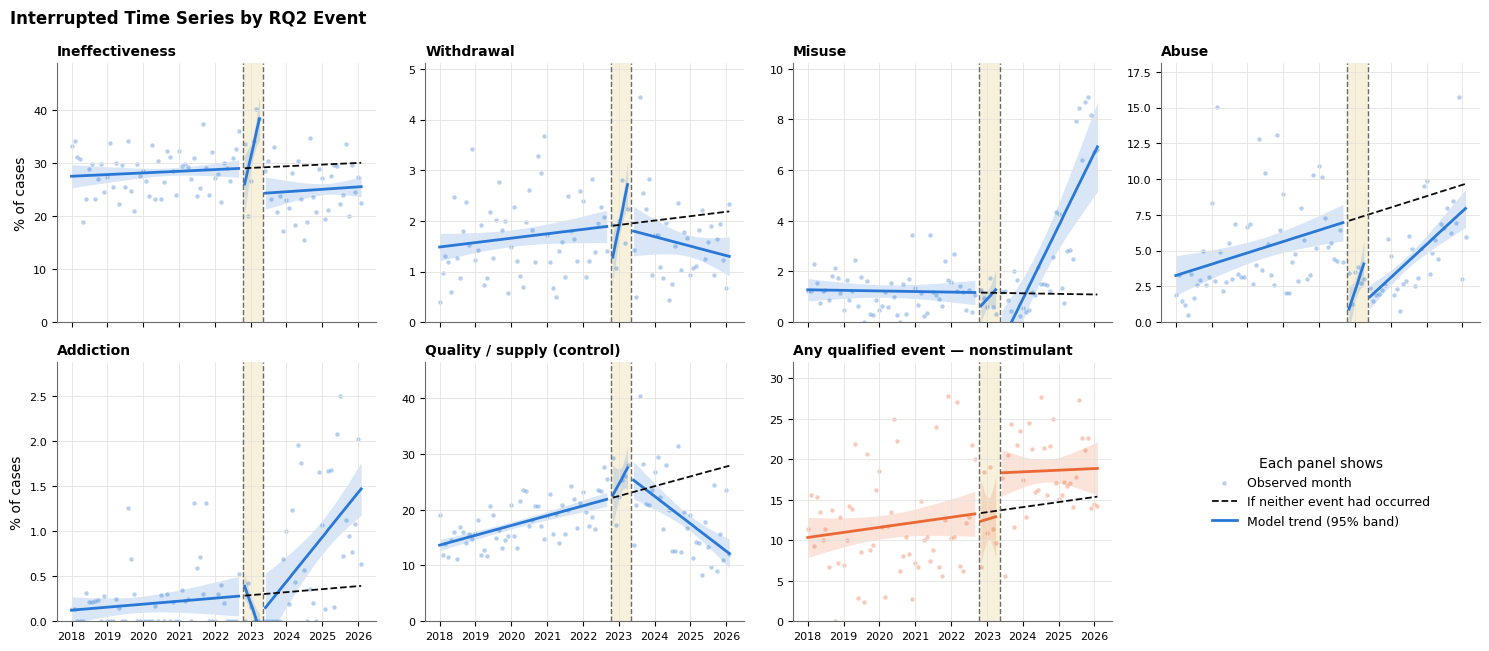

In [ ]:
# @title Interrupted Time Series by Event Group (Graph)
panels = [
    ("ineffectiveness_narrow", "STIMULANT"),
    ("withdrawal_narrow", "STIMULANT"),
    ("misuse_narrow", "STIMULANT"),
    ("abuse_narrow", "STIMULANT"),
    ("addiction_narrow", "STIMULANT"),
    ("product_quality_supply_narrow", "STIMULANT"),
    ("any_narrow", "NONSTIMULANT"),
]
fits = {}
fig, axes = plt.subplots(2, 4, figsize=(15, 6.6), sharex=True)
axes = axes.flatten()
for i in range(len(panels)):
    outcome, group = panels[i]
    name = LABELS[outcome]
    if group == "NONSTIMULANT":
        name = name + " — nonstimulant"
    fits[name], lines = fit_trend(outcome, group)
    draw_trend(axes[i], lines, COLORS[group], name)
    axes[i].tick_params(labelsize=8)
axes[7].axis("off")
handles, labels = axes[0].get_legend_handles_labels()
axes[7].legend(handles, labels, loc="center", fontsize=9, title="Each panel shows")
axes[0].set_ylabel("% of cases")
axes[4].set_ylabel("% of cases")
fig.suptitle(
    "Interrupted Time Series by RQ2 Event",
    fontweight="bold",
    x=0.01,
    ha="left",
)
fig.tight_layout()
plt.show()

#### Interrupted Time Series by Event Group Summary:
Ineffectiveness has the same shape as the main series and due to accounting for most of the total cases. Misuse and addiction are flat until the label change and then climb sharply. Abuse dips at the shortage and then recovers, nearing it's counterfactual. Withdrawal shows a devergence from it's counterfactual. The quality/supply control climbs sharply through the shortage and then falls steadily after the label change. The nonstimulant series sits higher after the label change, but its interval at the break is wide, so the model cannot tell if a jump occurs of if this is related to noise. Ineffectiveness drives the main result, misuse and addiction carry the label change rise, and the comparison and control series behave as expected.



### The four effect estimates for every series
Figures 4 and 5 show shapes; this chart shows the numbers behind them, with
their 95% intervals. An interval that does not cross the zero line is a change larger than
chance. Filled markers are still significant after
adjusting for the five tests.

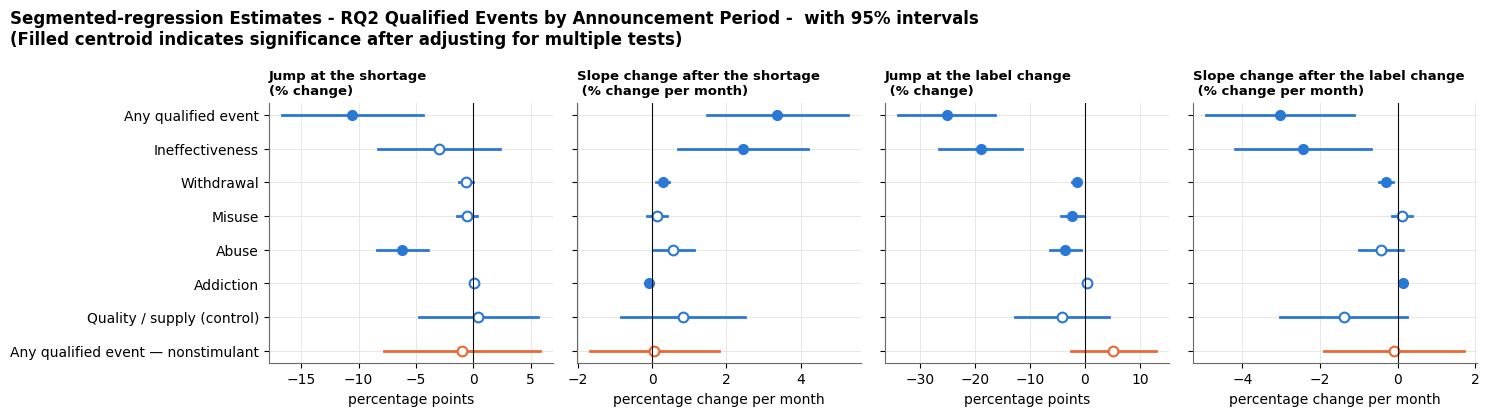

,Jump at the shortage\n(% change),Slope change after the shortage\n (% change per month),Jump at the label change\n (% change),Slope change after the label change\n (% change per month)
Any qualified event,-10.55 (-16.71 to -4.38),+3.37 (+1.48 to +5.27),-25.19 (-34.05 to -16.33),-3.04 (-4.93 to -1.14)
Ineffectiveness,-3.00 (-8.28 to +2.29),+2.44 (+0.69 to +4.19),-18.98 (-26.58 to -11.38),-2.43 (-4.18 to -0.68)
Withdrawal,-0.62 (-1.22 to -0.02),+0.28 (+0.11 to +0.45),-1.49 (-2.29 to -0.70),-0.30 (-0.48 to -0.13)
Misuse,-0.53 (-1.39 to +0.34),+0.13 (-0.13 to +0.39),-2.32 (-4.31 to -0.34),+0.11 (-0.15 to +0.38)
Abuse,-6.18 (-8.43 to -3.94),+0.57 (+0.01 to +1.12),-3.58 (-6.41 to -0.75),-0.44 (-1.01 to +0.13)
Addiction,+0.10 (-0.13 to +0.34),-0.10 (-0.15 to -0.05),+0.42 (-0.03 to +0.87),+0.13 (+0.08 to +0.19)
Quality / supply (control),+0.43 (-4.74 to +5.61),+0.84 (-0.83 to +2.50),-4.17 (-12.69 to +4.35),-1.39 (-3.02 to +0.24)
Any qualified event — nonstimulant,-1.00 (-7.80 to +5.79),+0.06 (-1.68 to +1.80),+5.20 (-2.54 to +12.94),-0.09 (-1.89 to +1.71)


In [ ]:
# @title Summary Whisker Plots with Table
terms = {
    "shortage_level": "Jump at the shortage\n(% change)",
    "shortage_slope": "Slope change after the shortage\n (% change per month)",
    "label_level": "Jump at the label change\n (% change)",
    "label_slope": "Slope change after the label change\n (% change per month)",
}

all_fits = {"Any qualified event": fit}
all_fits.update(fits)
rows = {}
for name, f in all_fits.items():
    row = {}
    ci = f.conf_int()
    for t in terms:
        row[t] = f.params[t]
        row[t + "_low"] = ci.loc[t, 0]
        row[t + "_high"] = ci.loc[t, 1]
        row[t + "_p"] = f.pvalues[t]
    rows[name] = row
estimates = pd.DataFrame(rows).T

for t in terms:
    estimates[t + "_p_adj"] = estimates[t + "_p"]
    estimates.loc[singles, t + "_p_adj"] = holm(estimates.loc[singles, t + "_p"].tolist())

fig, axes = plt.subplots(1, 4, figsize=(15, 4.2), sharey=True)
y = np.arange(len(estimates))[::-1]
for ax, t in zip(axes, terms):
    for yi, name in zip(y, estimates.index):
        row = estimates.loc[name]
        color = COLORS["STIMULANT"]
        if "nonstimulant" in name:
            color = COLORS["NONSTIMULANT"]
        ax.plot([row[t + "_low"], row[t + "_high"]], [yi, yi], color=color, lw=2)
        if row[t + "_p_adj"] < 0.05:
            ax.plot(row[t], yi, "o", ms=7, color=color)
        else:
            ax.plot(row[t], yi, "o", ms=7, color="white", mec=color, mew=1.5)
    ax.axvline(0, color=INK, lw=0.8)
    ax.set_title(terms[t], fontsize=9.5)
    if "slope" in t:
        ax.set_xlabel("percentage change per month")
    else:
        ax.set_xlabel("percentage points")
axes[0].set_yticks(y, estimates.index)
fig.suptitle(
    "Segmented-regression Estimates - RQ2 Qualified Events by Announcement Period -  with 95% intervals\n"
    "(Filled centroid indicates significance after adjusting for multiple tests)",
    fontweight="bold",
    x=0.01,
    ha="left",
)
fig.tight_layout()
plt.show()

table = pd.DataFrame(index=estimates.index)
for t in terms:
    table[terms[t]] = [
        f"{r[t]:+.2f} ({r[t + '_low']:+.2f} to {r[t + '_high']:+.2f})"
        for _, r in estimates.iterrows()
    ]
table

This chart shows the actual numbers behind behind the prior graphics with their 95% intervals.

#### Segmented-regression Estimates Summary:
The jump at the label change is the clearest estimate for the main series and for ineffectiveness group. Abuse has a clear drop from the shortage. Addiction has a small rise in slope after the label change. None of the nonstimulant intervals excludes zero, which supports considering the announcements as stimulant specific events even though the
nonstimulant average rose.
----



## Analysis (sorta)

## RQ2 - Conclusion

Reporting patterns changed at both announcements, but the evidence is much stronger for the May 2023 label change. Following the announcement, the share of stimulant reports listing a RQ2 qualified event dropped by about 25 points, mainly due to fewer reports identifying the medication as ineffective. However, RQ2 qualified events picked back slowly, and the misuse and addiction terms that the new label named became increasingly more common, mostly in 2025. Around the October 2022 shortage, reports of ineffectiveness and of product availability/quality rose. The size and timing of the shortage effect depend on modeling choices and vary due to one batch of Swedish reports (bulk reporting) that arrived during the shortage.

H2 is supported for the label change and partly for the shortage. Nonstimulant reports show no clear break at either date, which points to stimulant-specific causes, although their
average precentage with a qualified event did increase after the label change.

A change in reports can indicate increased hazard, more awareness, or both. A new warning makes people (individuals and health practitioners) more likely to notice and report what it identifies. The results show that a shortage and additional warnings both impact on what gets reported; they do not show that the medications became more or less safe.

**Subnotes:** Only six months fall between the two announcements, so the shortage estimates rely or indicate upon much less specific data, as it may be blended into the labeling announcement. Addiction and withdrawal have much lower reportable incidents. Reports do not tell us how many people took stimulants each month. The nonstimulant comparison is a side-by-side look, and not a separate statistical test.